<a href="https://colab.research.google.com/github/Tavarisco/DataCamp-Projects/blob/main/Netflix_analise.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Netflix**! O que começou em 1997 como um serviço de aluguel de DVDs virou uma das maiores empresas de entretenimento e mídia do mundo.

Com a enorme quantidade de filmes e séries disponíveis na plataforma, esta é uma ótima oportunidade para você exercitar suas habilidades de análise exploratória de dados e mergulhar no universo do entretenimento.

Você trabalha em uma produtora que se especializa em estilos nostálgicos. Você quer pesquisar filmes lançados nos anos 1990. Vamos explorar os dados da Netflix e fazer uma análise exploratória para entender melhor essa década incrível do cinema!

Você recebeu o conjunto de dados `netflix_data.csv`, junto com a tabela a seguir que detalha os nomes e as descrições das colunas. Fique à vontade para explorar mais depois de enviar!

## Os dados
### **netflix_data.csv**
| Column | Description |
|--------|-------------|
| `show_id` | ID do programa |
| `type` | Tipo de programa |
| `title` | Título do programa |
| `director` | Diretor(a) do programa |
| `cast` | Elenco do programa |
| `country` | País de origem |
| `date_added` | Data de inclusão na Netflix |
| `release_year` | Ano de lançamento na Netflix |
| `duration` | Duração do programa em minutos |
| `description` | Descrição do programa |
| `genre` | Gênero do programa |

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
# Importing pandas and matplotlib
import pandas as pd
import matplotlib.pyplot as plt

# Read in the Netflix CSV as a DataFrame
netflix_df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/DataCamp projetos/workspace/netflix_data.csv")

In [5]:
# Start coding here! Use as many cells as you like

In [6]:
movie = netflix_df[netflix_df['type'] == 'Movie']
dur = netflix_df[netflix_df['duration'] > 90]
year = netflix_df[netflix_df['release_year'] == 1990]
genre = netflix_df[netflix_df['genre'] == 'Action']
movie_1990_1999 = movie[(movie['release_year'] < 2000) & (movie['release_year'] >= 1990)]
movie_action = movie_1990_1999[movie_1990_1999['genre'] == 'Action']
movie_action90dur = movie_action[movie_action['duration'] > 90]

In [7]:
movie_action

,show_id,type,title,director,cast,country,date_added,release_year,duration,description,genre
352,s508,Movie,Andaz Apna Apna,Rajkumar Santoshi,"Aamir Khan, Salman Khan, Raveena Tandon, Karis...",India,"May 11, 2020",1994,160,Broke and with no concrete plans for the futur...,Action
431,s628,Movie,Austin Powers: The Spy Who Shagged Me,Jay Roach,"Mike Myers, Heather Graham, Michael York, Robe...",United States,"December 1, 2019",1999,95,When diabolical genius Dr. Evil travels back i...,Action
468,s688,Movie,Bad Boys,Michael Bay,"Will Smith, Martin Lawrence, Téa Leoni, Tchéky...",United States,"October 1, 2019",1995,119,"In this fast-paced actioner, two Miami narcoti...",Action
515,s757,Movie,Barsaat,Rajkumar Santoshi,"Twinkle Khanna, Bobby Deol, Danny Denzongpa, R...",India,"April 1, 2018",1995,166,A naïve young man and a rich city girl fall in...,Action
675,s1003,Movie,Blue Streak,Les Mayfield,"Martin Lawrence, Luke Wilson, Peter Greene, Da...",Germany,"January 1, 2021",1999,94,A jewel thief returns to his hiding place afte...,Action
815,s1236,Movie,Casino Tycoon,Wong Jing,Wong Jing,Hong Kong,"August 1, 2018",1992,125,"When Japanese troops invade Hong Kong, young B...",Action
816,s1237,Movie,Casino Tycoon 2,Wong Jing,Dennis Chan,Hong Kong,"August 16, 2018",1992,108,Casino mogul Benny Ho wields enormous power. B...,Action
1018,s1605,Movie,Dante's Peak,Roger Donaldson,"Pierce Brosnan, Linda Hamilton, Elizabeth Hoff...",United States,"September 1, 2019",1997,108,When a volcanologist comes to investigate the ...,Action
1179,s1850,Movie,Dragonheart,Rob Cohen,"Sean Connery, Dennis Quaid, David Thewlis, Pet...",United States,"January 1, 2020",1996,103,In ancient times when majestic fire-breathers ...,Action
1288,s2039,Movie,EVANGELION: DEATH (TRUE)²,Hideaki Anno,"Megumi Ogata, Kotono Mitsuishi, Megumi Hayashi...",Japan,"June 21, 2019",1998,69,"Fifteen years after the Second Impact, apathet...",Action


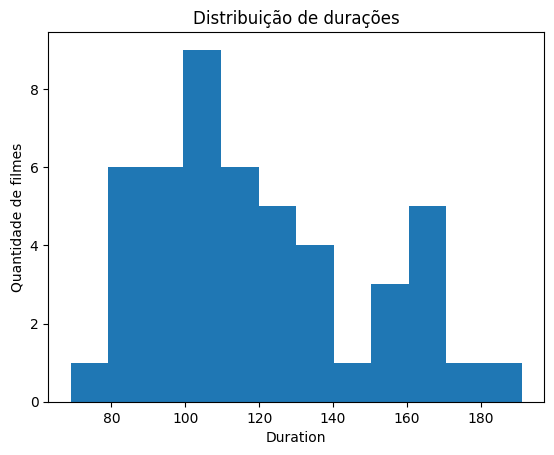

In [8]:
plt.hist(movie_action['duration'], bins=12)
plt.title('Distribuição de durações')
plt.xlabel('Duration')
plt.ylabel('Quantidade de filmes')
plt.show()

In [9]:
contador = 0
for idx, row in movie_action.iterrows():
    if row['duration'] < 90:
        contador = contador + 1
        print(f"{contador} - {row['title']}")
    short_movie_count = contador
print(short_movie_count)

1 - EVANGELION: DEATH (TRUE)²
2 - Hero
3 - Look Out, Officer
4 - Passenger 57
5 - Rumble in the Bronx
6 - The Bare-Footed Kid
7 - The End of Evangelion
7


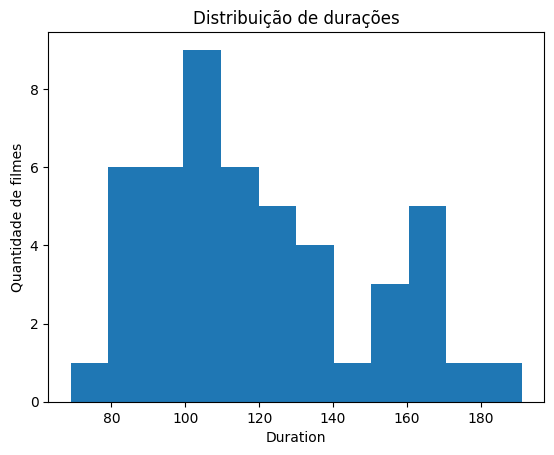

105

In [10]:
contagens, limites, _ = plt.hist(movie_action['duration'], bins=12)
plt.title('Distribuição de durações')
plt.xlabel('Duration')
plt.ylabel('Quantidade de filmes')
plt.show()

indice_maior = contagens.argmax()
inicio = limites[indice_maior]
fim = limites[indice_maior + 1]

filmes_mais_frequentes = movie_action[
    (movie_action['duration'] >= inicio) & (movie_action['duration'] < fim)
]

duration = filmes_mais_frequentes['duration'].sum() / 9
duration = int(duration)
duration